In [1]:

# ==========================================
# EV CHARGING DEMAND - MODEL EXPLAINABILITY
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Locate project folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "ChargingRecords_Cleaned.csv"
)

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)

df = df.dropna(subset=["StartDatetime", "Demand"]).copy()

# Feature engineering
df["StartHour"] = df["StartDatetime"].dt.hour
df["StartMonth"] = df["StartDatetime"].dt.month
df["StartDayOfWeek"] = df["StartDatetime"].dt.dayofweek
df["StartDayOfMonth"] = df["StartDatetime"].dt.day
df["IsWeekend"] = (df["StartDayOfWeek"] >= 5).astype(int)

# Prepare features and target
feature_columns = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "StartHour",
    "StartMonth",
    "StartDayOfWeek",
    "StartDayOfMonth",
    "IsWeekend"
]

X = df[feature_columns].copy()
y = df["Demand"].copy()

X = pd.get_dummies(
    X,
    columns=["Location"],
    drop_first=False,
    dtype=int
)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Evaluate model
y_pred = rf_model.predict(X_test)

print("MODEL TRAINED SUCCESSFULLY")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R2:", round(r2_score(y_test, y_pred), 4))

MODEL TRAINED SUCCESSFULLY
Training records: 58260
Testing records: 14566
MAE: 9.4409
RMSE: 12.5576
R2: 0.1249


TOP 15 IMPORTANT FEATURES
                    Feature  Importance
                  StartHour    0.297508
            StartDayOfMonth    0.207501
                 StartMonth    0.155134
             StartDayOfWeek    0.101641
                ChargerType    0.038479
             ChargerCompany    0.028611
            Location_market    0.023299
           Location_camping    0.021120
             Location_hotel    0.018151
       Location_public area    0.015055
         Location_apartment    0.014759
Location_public institution    0.013775
                  IsWeekend    0.012213
            Location_resort    0.011320
           Location_company    0.010949


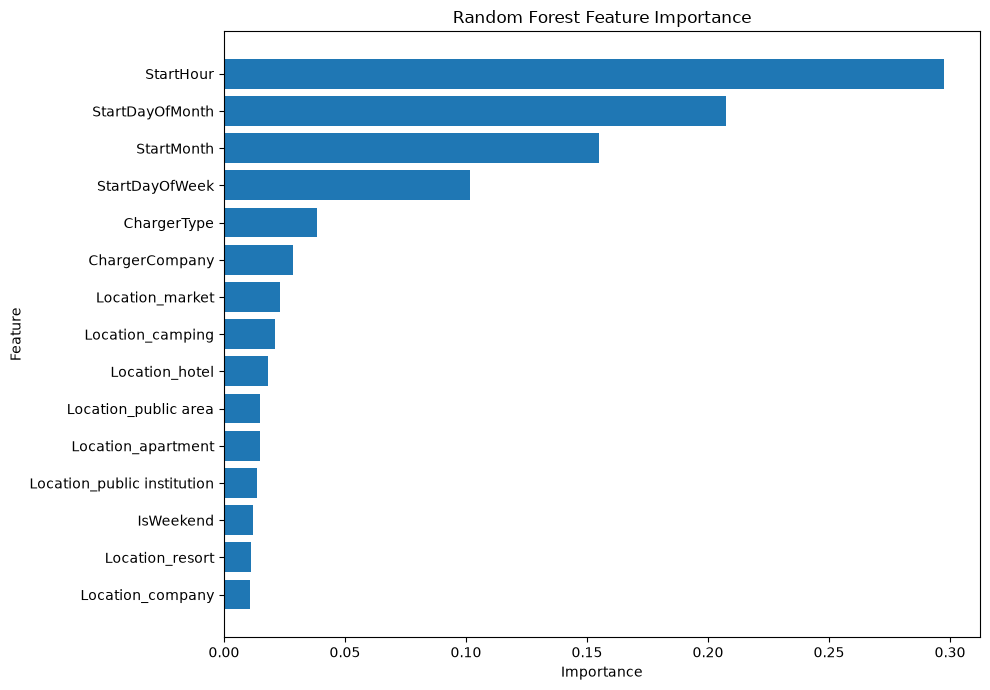

In [2]:

# ==========================================
# FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("TOP 15 IMPORTANT FEATURES")
print(feature_importance.head(15).to_string(index=False))

plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    "Importance", ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

SHAP explanations generated successfully!


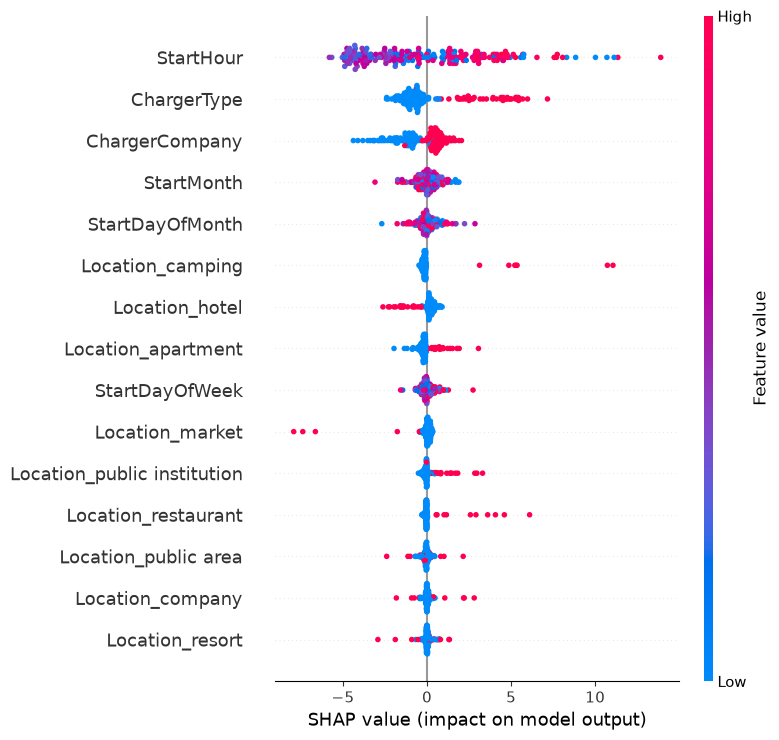

Actual demand: 19.72
Predicted demand: 18.9702


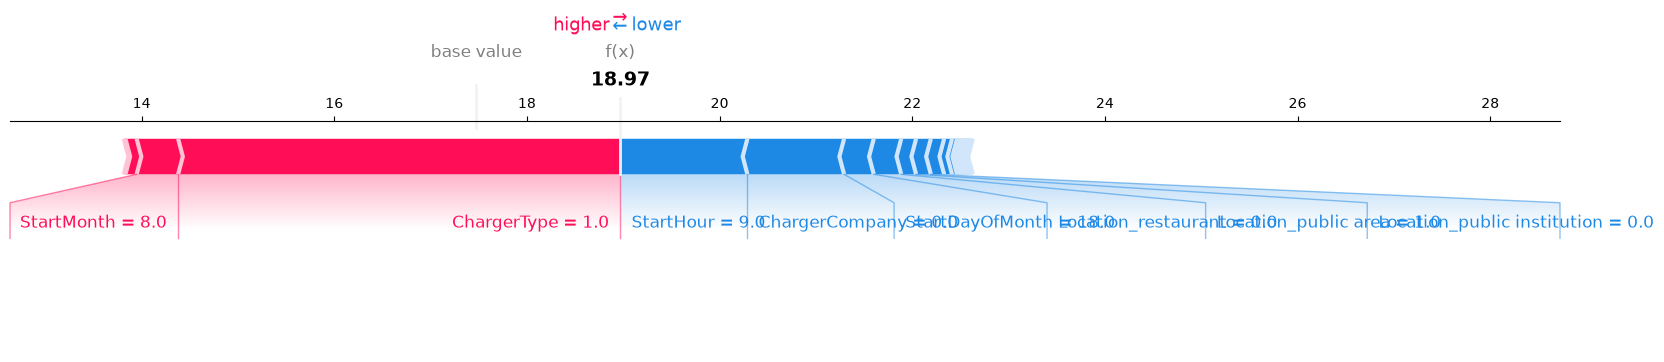

In [5]:

# ==========================================
# SHAP EXPLAINABILITY
# ==========================================

import shap

# Use a sample to keep explanations efficient
X_background = X_train.sample(
    n=min(100, len(X_train)), random_state=42
)

X_explain = X_test.sample(
    n=min(200, len(X_test)), random_state=42
)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_explain)

print("SHAP explanations generated successfully!")

# Global explanation
shap.summary_plot(
    shap_values,
    X_explain,
    max_display=15
)

# Explain one individual prediction
shap_index = 0

print("Actual demand:", y_test.loc[X_explain.index[shap_index]])
print(
    "Predicted demand:",
    round(rf_model.predict(
        X_explain.iloc[[shap_index]]
    )[0], 4)
)

shap.force_plot(
    explainer.expected_value,
    shap_values[shap_index],
    X_explain.iloc[shap_index],
    matplotlib=True
)
plt.show()

Actual demand: 10.32
Predicted demand: 15.4642


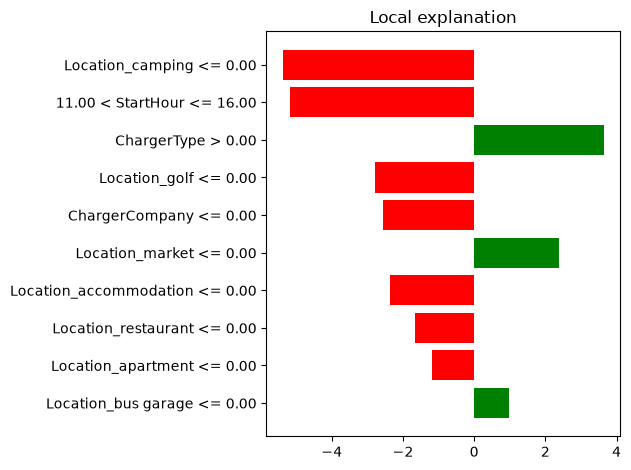

In [11]:

# ==========================================
# LIME EXPLAINABILITY
# ==========================================

from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=X_train.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

lime_index = 0
lime_record = X_test.iloc[lime_index]

lime_explanation = lime_explainer.explain_instance(
    data_row=lime_record.to_numpy(dtype=float),
    predict_fn=lambda data: rf_model.predict(
    pd.DataFrame(data, columns=X_train.columns)
    ),
    num_features=10
)

print("Actual demand:", y_test.loc[lime_record.name])
print(
    "Predicted demand:",
    round(rf_model.predict(
        X_test.iloc[[lime_index]]
    )[0], 4)
)

lime_explanation.as_pyplot_figure()
plt.tight_layout()
plt.show()

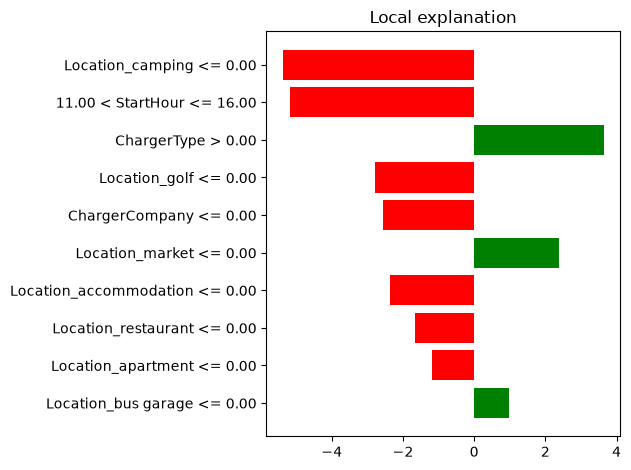


LIME FEATURE CONTRIBUTIONS
Location_camping <= 0.00: -5.3812
11.00 < StartHour <= 16.00: -5.1834
ChargerType > 0.00: 3.6455
Location_golf <= 0.00: -2.7737
ChargerCompany <= 0.00: -2.5458
Location_market <= 0.00: 2.3819
Location_accommodation <= 0.00: -2.3740
Location_restaurant <= 0.00: -1.6491
Location_apartment <= 0.00: -1.1953
Location_bus garage <= 0.00: 0.9655


In [12]:
# Display the LIME explanation
lime_explanation.as_pyplot_figure()
plt.tight_layout()
plt.show()

# Print feature contributions
print("\nLIME FEATURE CONTRIBUTIONS")
for feature, contribution in lime_explanation.as_list():
    print(f"{feature}: {contribution:.4f}")

In [13]:

# Save LIME explanation results
lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature_Condition", "Contribution"]
)

lime_results["Effect"] = np.where(
    lime_results["Contribution"] > 0,
    "Increases prediction",
    "Decreases prediction"
)

OUTPUT_PATH = PROJECT_ROOT / "reports"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

lime_results.to_csv(
    OUTPUT_PATH / "lime_explanation.csv",
    index=False
)

print("LIME explanation saved successfully!")
print(OUTPUT_PATH / "lime_explanation.csv")

LIME explanation saved successfully!
c:\Users\Dell\Documents\EV_Charging_Demand_Analysis\reports\lime_explanation.csv
